# 22 — How far to trust the live race: backtests

**In brief**
- **Question:** At a given point of the season, how often has the live race (notebook 12) already had the eventual winner near the top? And over the last five seasons, how did our three lists (end of the previous season, end of preseason, mid-January) compare with the real vote?
- **Answer:** After a week the board is a rough shortlist; after one to two months a real shortlist; from about the All-Star break a real ranking. At day 22 the eventual winner was in our top 7 in 9 of 15 past seasons (leave-one-out). In the strict five-season test, the mid-January list had the winner in its top 7 every season.
- **Decisions** ([decision log](../docs/DECISIONS.md)): D22–D24, D30, D32, D38–D42.
- **Where it fits:** The backtests behind the live race. They were sections 12A and 12D of notebook 12 until 13 November 2026, when they moved here so that the daily update no longer recomputes them. Re-run this notebook only when the model changes (from 2027-28; the model is frozen until then, D44).
- **Dated:** findings written 30 October 2026 and re-run 12 November 2026 with the game-score turning point (D41) and the established-star inputs (D42); moved here unchanged on 13 November 2026.


In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from nba_api.stats.endpoints import leaguegamelog
from unicorn.gamelogs import GAMELOG_SEASONS, build_game_table, load_game_logs, mip_candidates
from unicorn.labels import MIP_WINNERS
from unicorn.mip import AGE, GAMELOG_DEFENSE, GAMELOG_DELTAS, RELATIVE, SECOND_YEAR, TEAM, ChoiceModel
from unicorn.plotting import BLUE, FIG_DIR, INK, INK2, MUTED, ORANGE, SERIES, SURFACE, apply_style
from unicorn.raw import PROJECT_ROOT, fetch

warnings.filterwarnings("ignore")
apply_style()
LIVE, LIVE_START, L2 = "2026-27", 2026, 3.0
from functools import lru_cache
from unicorn.gamelogs import all_star_breaks
from unicorn.mip_history import TURN_CHOICES, choose_turning_point, with_turn
from unicorn.preseason import TURNING_POINT       # the preseason model's turning point (notebook 11), used in 12C-12D
from unicorn.allstars import add_prior_allstar, load_selections
from unicorn.hot_start import add_stale
SEL = load_selections()
from unicorn.mip_eval import LIVE_LEVEL, LIVE_TURN_CHOICES   # the turning point is on the baseline season's game score (D41)
from unicorn.established import STAR_INPUTS   # baseline game score 16+, baseline season in the star tier (D42)
EARLY_BASE = GAMELOG_DELTAS + GAMELOG_DEFENSE + RELATIVE + TEAM + AGE + SECOND_YEAR + [LIVE_LEVEL, "prior_allstar", "stale"] + STAR_INPUTS   # D38, D39, D42
EARLY = EARLY_BASE + ["over_turn"]                # over_turn = baseline game score above the turning point the data chose (D32, D41)

import unicorn.live_race as LR
games = LR.live_games(refresh=False)               # cached game logs; only past seasons are scored here
live_games = games[games["season"] == LIVE]


In [2]:
# candidates on any day, in every past season (src/unicorn/live_race.py); the 2026-27 rows are never scored here
ps = pd.read_parquet(PROJECT_ROOT / "data" / "processed" / "player_season.parquet")
ps_live = LR.player_table_with_live_season(ps)

def race(day):
    """Eligible candidates in every season, using only games up to `day` days after that season's opener.
    Previous winners included; already an All-Star (D38) and back from a lost season (D39) added."""
    return LR.race(games, ps_live, day, SEL)

def pick_turn(train):
    """Turning point chosen by season-grouped cross-validation on past seasons only; None = no turning point."""
    return choose_turning_point(train, EARLY_BASE, LIVE_LEVEL, grid=LIVE_TURN_CHOICES)

def turn_label(k):
    return "none" if k is None else f"game score {k:g}"


## 22A — How much can a few weeks of games tell us?

Before looking at the leaders: in past seasons, where did the **eventual winner** rank at the same point of the season? Each season is predicted by a model trained on the other seasons, cut at the same day. This is the **leave-one-out** test, which is kinder than the strict test because later seasons help train the model; 22B gives the strict version for the last five seasons.

In [3]:
def winner_ranks(day):
    c = race(day)
    h = c[c["season"] != LIVE]
    out = {}
    for s in sorted(h["season"].unique()):
        te = h[h["season"] == s]
        if not te["mip"].any():
            out[s] = np.nan          # the eventual winner had not yet played enough to be a candidate
            continue
        tr = h[h["season"] != s]
        k = pick_turn(tr)                       # chosen without the held-out season
        p = ChoiceModel(EARLY, L2).fit(with_turn(tr, LIVE_LEVEL, k)).predict_proba(with_turn(te, LIVE_LEVEL, k))
        out[s] = p.rank(ascending=False, method="min")[te["mip"]].iloc[0]
    return pd.Series(out)

DAYS = [2, 7, 14, 22, 30, 60, 90, 120]          # day 22 = where the live race stood when this was written (11 November)
ranks = pd.DataFrame({d: winner_ranks(d) for d in DAYS})
curve = pd.DataFrame({"winner #1": (ranks == 1).sum(), "winner in top 3": (ranks <= 3).sum(), "winner in top 7": (ranks <= 7).sum(),
                      "winner in top 20": (ranks <= 20).sum(), "median winner rank": ranks.median()}).T
curve.columns = [f"day {d}" for d in DAYS]
print(f"out of {len(ranks)} past seasons (2011-12 → 2025-26)")
curve.round(1)

out of 15 past seasons (2011-12 → 2025-26)


,day 2,day 7,day 14,day 22,day 30,day 60,day 90,day 120
winner #1,2.0,3.0,3.0,4.0,4.0,6.0,6.0,6.0
winner in top 3,4.0,6.0,6.0,8.0,7.0,8.0,9.0,9.0
winner in top 7,5.0,7.0,8.0,9.0,9.0,11.0,13.0,12.0
winner in top 20,9.0,10.0,11.0,13.0,13.0,13.0,15.0,15.0
median winner rank,15.0,9.0,5.0,3.0,4.0,3.0,2.0,2.0


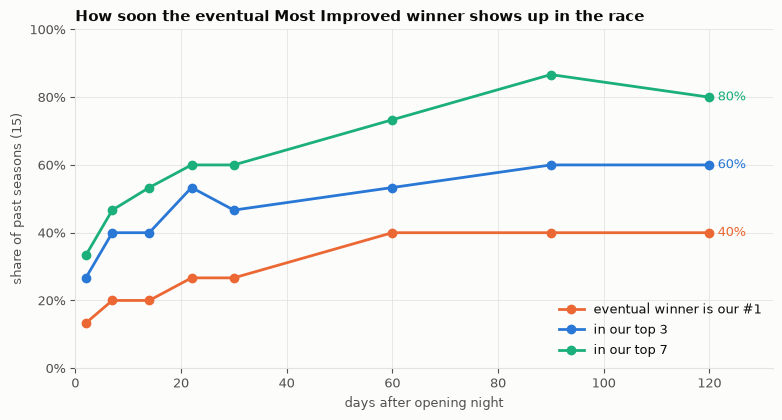

In [4]:
fig, ax = plt.subplots(figsize=(9, 4.4))
n = len(ranks)
for (label, k), col in zip([("eventual winner is our #1", 1), ("in our top 3", 3), ("in our top 7", 7)], [ORANGE, BLUE, SERIES[2]]):
    share = [(ranks[d] <= k).sum() / n for d in DAYS]
    ax.plot(DAYS, share, marker="o", color=col, label=label)
    ax.annotate(f"{share[-1]:.0%}", (DAYS[-1], share[-1]), xytext=(6, 0), textcoords="offset points", va="center", fontsize=9, color=col)
ax.set_ylim(0, 1); ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}"); ax.set_xlim(0, DAYS[-1] + 12)
ax.set_xlabel("days after opening night"); ax.set_ylabel(f"share of past seasons ({n})")
ax.legend(frameon=False, loc="lower right")
ax.set_title("How soon the eventual Most Improved winner shows up in the race", loc="left")
fig.savefig(FIG_DIR / "22_race_by_day.png", dpi=150, bbox_inches="tight")

### 22A findings (re-run 12 November 2026 with D41 and D42)

- **After two days (one game for most teams), the race says very little.** The eventual winner was in our top 7 in 5 of 15 past seasons; median rank 15. That's no better than the preseason prediction in notebook 11.
- **After about a week (3–5 games) it starts to mean something:** at day 7 the winner was in our top 7 in 7 of 15 seasons, median rank 9.
- **By day 30 (about 14 games) the winner's median rank is 4; by day 60 he's in the top 7 in 11 of 15 seasons, and by day 90 in 13.** What keeps improving after that is the order at the top (#1 in 6 of 15 by day 60).
- **Where the live race stood when this was written (day 22 after opening night, 11 November):** the winner was in our top 7 in 9 of 15 seasons, median rank 3. So treat today's board as a rough shortlist.
- **Rule of thumb:** a rough shortlist after a week, a real shortlist after one to two months, and a real ranking from about the All-Star break.
- **How far to trust the chances:** on the whole they are honest; players given 5% win about 5% of the time (notebook 20). The exception is a big early favourite: players given 25%+ before about day 45 have won about 1 time in 6, not 2 in 5. The race prints a note when that happens (D40).

## 22B — Backtest: three views of the last five seasons

For each season from 2021-22 to 2025-26, four lists:
1. **End of the previous season:** last season only (the 11 model without preseason inputs).
2. **End of preseason:** the 11 model.
3. **Mid-season:** the live race (notebook 12) at **day 85** (about halfway through a normal season, mid-January).
4. **What actually happened:** the real voting top 7 (Basketball-Reference, used only to score our lists).

**Strict test:** every list comes from a model trained only on **earlier** seasons, so it is what we would have said at the time. Candidate rules are the same as above (no exclusions; turning point at 20 points before the season, and on game score, chosen from earlier seasons, at mid-season).

In [5]:
# the preseason views (notebook 11's model), for the end-of-previous-season and preseason lists
from unicorn.preseason import ESTABLISHED, RETURNING, LAST_SEASON_LEAN, MOMENTUM, PROFILE, TURN, USED, add_pool_flags, add_star_left, add_turning_point, load_preseason, preseason_frame

past_games = games[games["season"] != LIVE]
pre = load_preseason(regular=games, refresh_latest=False)
F = add_star_left(add_turning_point(add_pool_flags(preseason_frame(pre, past_games, ps), MIP_WINNERS)), pre, games)   # no exclusions
F = add_stale(add_prior_allstar(F, SEL))
FH = F[F["season"] != LIVE].reset_index(drop=True)


In [6]:
# FIVE_SEASONS
from unicorn.bref import all_mip_voting, attach_player_ids

BACK = ["2021-22", "2022-23", "2023-24", "2024-25", "2025-26"]
DAY_MID = 85
votes = attach_player_ids(all_mip_voting(), games)
mid = race(DAY_MID)
FA = F[F["season"] != LIVE]

def walk_forward(train_all, test_all, features, season):
    m = ChoiceModel(features, L2).fit(train_all[train_all["season"] < season])
    t = test_all[test_all["season"] == season]
    out = t[["player_id", "player_name", "mip"]].assign(chance=m.predict_proba(t))
    out["rank"] = out["chance"].rank(ascending=False, method="first").astype(int)
    return out.sort_values("rank")

VIEWS = {"end of previous season": lambda s: walk_forward(FH, FA, LAST_SEASON_LEAN + PROFILE + MOMENTUM + TURN + ESTABLISHED + RETURNING, s),
         "end of preseason": lambda s: walk_forward(FH, FA, USED, s),
         f"mid-season (day {DAY_MID})": lambda s: mid_view(s)}

def mid_view(s):
    k = pick_turn(mid[mid["season"] < s])        # earlier seasons only
    m = with_turn(mid, LIVE_LEVEL, k)
    return walk_forward(m[m["season"] != LIVE], m, EARLY, s)
lists = {(s, v): f(s) for s in BACK for v, f in VIEWS.items()}

rows = []
for s in BACK:
    real = votes[(votes["season"] == s) & (votes["vote_rank"] <= 7)]
    voted = set(votes.loc[votes["season"] == s, "player_id"].dropna().astype(int))
    winner = real.loc[real["vote_rank"] == 1, "player"].iloc[0]
    for v in VIEWS:
        L7 = lists[(s, v)]
        w = L7[L7["mip"]]
        top = L7.head(7)
        rows.append({"season": s, "view": v, "winner": winner, "winner's rank": int(w["rank"].iloc[0]) if len(w) else None,
                     "of our 7 in the real top 7": int(top["player_id"].isin(real["player_id"]).sum()),
                     "of our 7 who got any vote": int(top["player_id"].isin(voted).sum())})
scores = pd.DataFrame(rows)
summary = scores.groupby("view", sort=False).agg(**{"winner in our top 7 (of 5)": ("winner's rank", lambda r: int((r <= 7).sum())),
                                                   "median winner rank": ("winner's rank", "median"),
                                                   "of our 7 in the real top 7 (avg)": ("of our 7 in the real top 7", "mean"),
                                                   "of our 7 who got any vote (avg)": ("of our 7 who got any vote", "mean")})
display(scores.pivot(index="season", columns="view", values="winner's rank")[list(VIEWS)].rename_axis(columns="winner's rank in each view"))
summary.round(1)

winner's rank in each view,end of previous season,end of preseason,mid-season (day 85)
season,,,
2021-22,27,7,1
2022-23,26,4,1
2023-24,1,13,3
2024-25,41,6,5
2025-26,40,24,4


,winner in our top 7 (of 5),median winner rank,of our 7 in the real top 7 (avg),of our 7 who got any vote (avg)
view,,,,
end of previous season,1,27.0,0.6,1.2
end of preseason,3,7.0,1.0,1.4
mid-season (day 85),5,3.0,3.6,4.0


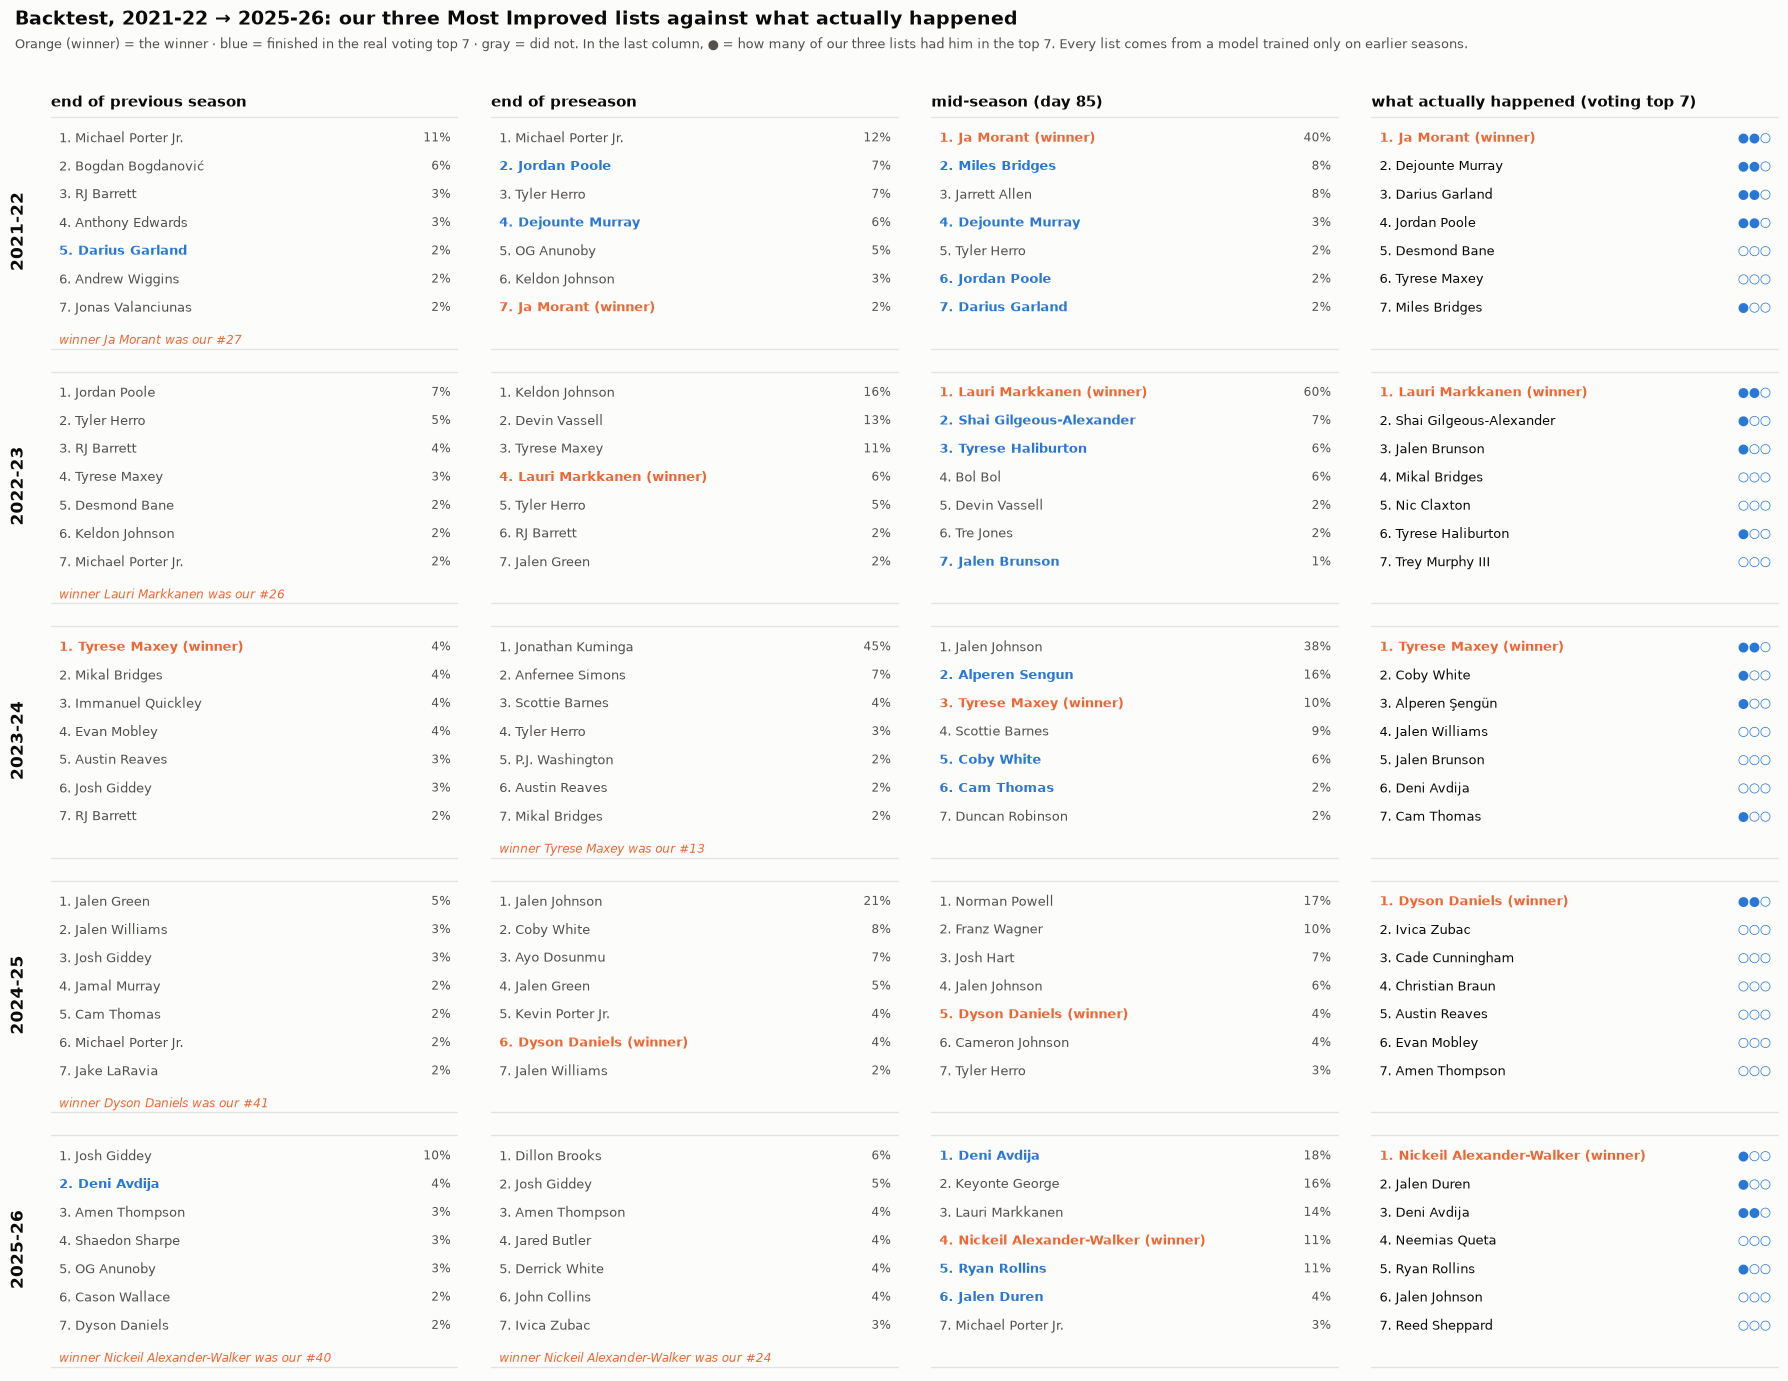

In [7]:
fig, axes = plt.subplots(len(BACK), 4, figsize=(18, 2.55 * len(BACK) + 1.0))
heads = list(VIEWS) + ["what actually happened (voting top 7)"]
for i, s in enumerate(BACK):
    real = votes[(votes["season"] == s)].sort_values("vote_rank").head(7)
    real_ids = set(real["player_id"].dropna().astype(int))
    ours = [set(lists[(s, v)].head(7)["player_id"]) for v in VIEWS]
    for j in range(4):
        ax = axes[i, j]; ax.axis("off"); ax.set_xlim(0, 1); ax.set_ylim(7.6, -0.9)
        if i == 0:
            ax.text(0, -1.0, heads[j], fontsize=10.5, fontweight="bold", color=INK, va="bottom")
        if j == 0:
            ax.text(-0.08, 3.3, s, fontsize=12, fontweight="bold", color=INK, rotation=90, va="center", ha="center")
        if j < 3:
            L7 = lists[(s, list(VIEWS)[j])]
            for k, r in enumerate(L7.head(7).itertuples()):
                hit = r.player_id in real_ids
                col = ORANGE if r.mip else (BLUE if hit else INK2)
                ax.text(0.02, k, f"{r.rank}. {r.player_name}{' (winner)' if r.mip else ''}", fontsize=9.3, color=col,
                        fontweight="bold" if (hit or r.mip) else "normal", va="center")
                ax.text(0.98, k, f"{r.chance:.0%}", fontsize=8.5, color=INK2, va="center", ha="right")
            w = L7[L7["mip"]]
            if len(w) and int(w["rank"].iloc[0]) > 7:
                ax.text(0.02, 7.15, f"winner {w['player_name'].iloc[0]} was our #{int(w['rank'].iloc[0])}", fontsize=8.3, color=ORANGE, va="center", style="italic")
            elif not len(w):
                ax.text(0.02, 7.15, "winner was not a candidate in this view", fontsize=8.3, color=ORANGE, va="center", style="italic")
        else:
            for k, r in enumerate(real.itertuples()):
                pid = int(r.player_id) if pd.notna(r.player_id) else -1
                n_lists = sum(pid in o for o in ours)
                ax.text(0.02, k, f"{r.vote_rank}. {r.player}{' (winner)' if r.vote_rank == 1 else ''}", fontsize=9.3,
                        color=ORANGE if r.vote_rank == 1 else INK, fontweight="bold" if r.vote_rank == 1 else "normal", va="center")
                ax.text(0.98, k, "●" * n_lists + "○" * (3 - n_lists), fontsize=9, color=BLUE, va="center", ha="right")
        ax.add_patch(plt.Rectangle((-0.02, -0.75), 1.04, 8.2, fill=False, edgecolor="#e4e3df", linewidth=1))
fig.suptitle("Backtest, 2021-22 → 2025-26: our three Most Improved lists against what actually happened", x=0.01, y=1.0, ha="left", fontsize=14, fontweight="bold")
fig.text(0.01, 0.972, "Orange (winner) = the winner · blue = finished in the real voting top 7 · gray = did not. In the last column, ● = how many of our three lists had him in the top 7. "
         "Every list comes from a model trained only on earlier seasons.", ha="left", fontsize=9.5, color=INK2)
fig.subplots_adjust(left=0.03, right=0.99, top=0.925, bottom=0.01, wspace=0.08, hspace=0.06)
fig.savefig(FIG_DIR / "22_backtest_five_seasons.png", dpi=150, bbox_inches="tight")

### 22B findings (no exclusions, star flag, already an All-Star, back from a lost season; mid-season turning point on game score, chosen from earlier seasons only; re-run 12 November with D41 and D42)

| View (strict, 5 seasons) | Winner in our top 7 | Median winner rank | Of our 7 in the real voting top 7 | Of our 7 who got any vote |
|---|---|---|---|---|
| End of previous season | 1 of 5 | 27 | 0.6 | 1.2 |
| End of preseason | 3 of 5 | 7 | 1.0 | 1.4 |
| **Mid-season (day 85)** | **5 of 5** | **3** | **3.6** | **4.0** |

- **By mid-January the race is usually decided.** The eventual winner was #1 twice (Ja Morant, Lauri Markkanen), #3 once (Tyrese Maxey), #4 once (Nickeil Alexander-Walker) and #5 once (Dyson Daniels): in our top 7 every time. (Before D41 and D42, Maxey was 2nd and Daniels 10th.) On average, three or four of our seven finished in the real voting top 7.
- **Before a game is played, we catch some.**
  - **The end-of-previous-season list** had Maxey at #1 for 2023-24.
  - **The preseason list caught Markkanen** (#4; Donovan Mitchell had left Utah), **Daniels** (#6; Dejounte Murray had left Atlanta) and **Morant** (#7).
- **The All-Star and lost-season inputs helped most before the season.** The preseason median winner rank went from 15 to 7, and the end-of-previous-season median from 44 to 27.
- **Preseason moves the winner up in 4 of 5 seasons:** Morant 27 → 7, Markkanen 26 → 4, Daniels 41 → 6, Alexander-Walker 40 → 24. The exception is Maxey (1 → 13).
- **A new role is the key preseason clue.** Markkanen and Daniels were traded to teams that had just lost their star, and the star flag sees that. Alexander-Walker (24th) and Maxey (13th; James Harden left only after the season began) are the ones it can't see.
- **For 2026-27:** read the end-of-previous-season and preseason lists as "who is set up to improve", not "who will win", and check back around mid-January.